# AI Security 02360207 - HW1
## Advarserial Attacks on Image Classification Models

<table border="1" cellpadding="6">
<tr>
<th>Name</th>
<th>ID</th>
</tr>
<tr>
<td>Zina Assi</td>
<td>213813165</td>
</tr>
<tr>
<td>Abed-al-rahman Badran</td>
<td>325424752</td>
</tr>
<tr>
<td>Student 3</td>
<td>111111111</td>
</tr>
</table>

In this HW we are going to train and attack text classification models on a common image dataset $CFAR10$. 
Complete the notebook cells below. Submit your notebook file after a run. Make sure before submission that you filled the table above and that all the cells have been executed and have desired outputs. If you are a team of two students - no need to fill the details for student 3.
When you submit the file, please name it: hw1_vision_attacks_id1_id2_id3.ipynb (no id3 if you are a pair of students).

**Submission deadline: 2/12/2026**


# AI Usage
The purpose of this HW is to give you hands-on experience with white-box attacks on vision models: to see how the attack parameters change the result, and to understand how and why these attacks work.

With this in mind:
1. You **may** use generative AI tools to help you with this HW.
2. You are responsible for understanding every line of code you submit, and for being able to explain how and why the attack works.

 #### $Ex1.$ Define the following norms over the euclidean space $\mathbb{R}^d$ (double-click the cell to edit text):

For $x = (x_1, \dots, x_d) \in \mathbb{R}^d$:

* $L_0 = \|x\|_0 = \left|\{\, i \in \{1,\dots,d\} : x_i \neq 0 \,\}\right|$, the number of non-zero coordinates. (Strictly speaking this is not a true norm, because it is not homogeneous: $\|2x\|_0 = \|x\|_0 \neq 2\|x\|_0$ for $x \neq 0$.)

* $L_2 = \|x\|_2 = \sqrt{\sum_{i=1}^{d} x_i^2}$, the Euclidean length of $x$.

* $L_{\infty} = \|x\|_\infty = \max_{i \in \{1,\dots,d\}} |x_i|$, the largest absolute value of any coordinate.

As perturbation budgets: $L_0$ limits **how many** coordinates may change (by any amount), $L_2$ limits the **total energy** of the change, and $L_\infty$ limits **how much each single coordinate** may change.

#### $Ex2.$ Load the $CFAR10$ dataset and a pre-trained model on it using the code blow. Write an evaluation function, which gets a model and a dataloader, and returns the accuracy, micro and macro F1 scores of the model on the data. You can use sklearn.metrics functions for caluclating the metrics.

In [1]:
import torch
import torchvision
import torchvision.transforms as transforms
from sklearn.metrics import accuracy_score, f1_score

Load CFAR10 (already implemented for you):

In [2]:
transforms = transforms.Compose([
    transforms.ToTensor(),
    transforms.Normalize((0.5, 0.5, 0.5), (0.5, 0.5, 0.5))
])

test_dataset = torchvision.datasets.CIFAR10(root='./data', train=False, download=True, transform=transforms)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=128, shuffle=False)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")


Load a pre-traiend model on CFAR10 (already implemented for you):

In [3]:
# Loads a pretrained ResNet20 trained on CIFAR-10
model = torch.hub.load(
    'chenyaofo/pytorch-cifar-models', 
    'cifar10_resnet20', 
    pretrained=True
)

model.to(device)

Using cache found in C:\Users\zena4/.cache\torch\hub\chenyaofo_pytorch-cifar-models_master


CifarResNet(
  (conv1): Conv2d(3, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
  (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(16, 16, kernel_size

#### Visualization helpers (given)
The file `helper.py` (it must be in the same folder as this notebook; **do not modify it**) contains two functions that help you look at your results. Import them once (next cell):

```python
from helper import show_examples, animate_attack
```

---
**1. `show_examples` – original vs. perturbed images**

```python
show_examples(model, x_orig, x_pert, y, n=6, normalized=True, title='')
```

| argument | meaning |
|---|---|
| `model` | the classifier. It must accept images **in the same space** as `x_orig` / `x_pert` (see `normalized`). It is switched to eval mode |
| `x_orig`, `x_pert` | original and perturbed images, tensors of shape `[B, 3, 32, 32]`; `x_pert[i]` is the perturbed version of `x_orig[i]` |
| `y` | the true labels, shape `[B]` |
| `n` | number of examples to show (rows) |
| `normalized` | `True`: the images are in the normalised space of `test_loader` (as the dataloader returns them). `False`: the images are in $[0,1]$ pixel space |
| `title` | optional title of the figure |
| `mean`, `std` | the normalisation constants of `test_loader` – change them only if you changed the normalisation above (default: 0.5, 0.5) |

Each row shows **original | perturbation (amplified, with its $L_0$, $L_2$, $L_\infty$ size) | perturbed image**. The titles contain the true label, the model's prediction and its confidence (green = correct, red = wrong). Examples that the model classified correctly *before* the perturbation are shown first. The function only draws, it returns nothing.

Example – images taken from the dataloader (normalised space):
```python
x, y = next(iter(test_loader))                      # a batch of 128 normalised images
show_examples(model, x, x_perturbed, y, n=4, normalized=True, title='my perturbation')
```
If you work in pixel space (images in $[0,1]$), pass a model that takes such images (e.g. a small wrapper that normalises inside) together with `normalized=False`.

---
**2. `animate_attack` – a GIF of the attack process**

```python
animate_attack(model, x_orig, trajectory, y, normalized=True, path='attack_process.gif', fps=4, title='')
```

| argument | meaning |
|---|---|
| `model` | as above |
| `x_orig` | **one** original image, shape `[3, 32, 32]` |
| `trajectory` | the perturbed image **after every iteration** of your attack: a tensor `[K+1, 3, 32, 32]` (the starting point first, then one entry per iteration) |
| `y` | the true label of this image (an int) |
| `normalized` | as above |
| `path` | where the GIF is saved (it is also displayed in the notebook) |
| `fps` | speed of the animation, in iterations per second |
| `title` | optional title of the figure |
| `mean`, `std` | as above |

The GIF shows, for every iteration: the growing perturbation (amplified, with a fixed gain), the perturbed image with the model's prediction, the class probabilities, and the confidence in the true class. 

**You have to record the trajectory in your own PGD implementation**, for one image:
```python
history = [x + delta]                      # the starting point  (x: ONE image [3,32,32], delta: its perturbation)
for k in range(K):
    ...                                    # your PGD iteration
    history.append(x + delta)              # the perturbed image after every iteration
trajectory = torch.stack(history)          # [K+1, 3, 32, 32]
animate_attack(model, x, trajectory, y_true_of_x, normalized=...)
```
*Tip:* for a nice, slow animation run the attack on that image with a **small budget and tiny steps** (e.g. `eps = 2/255`, `alpha = eps/16`, 30 iterations) and start from `delta = 0`.

(`help(show_examples)` and `help(animate_attack)` print the same documentation.)

In [4]:
# The visualization helpers live in helper.py, next to this notebook (do not modify it)
from helper import show_examples, animate_attack

Run the model on the dataset and report accuracy, micro and macro F1.

In [5]:
def evaluate(model, dataloader):
    """Returns the (accuracy, micro F1, macro F1) of `model` on the data in `dataloader`."""
    model.eval()  # use the stored BatchNorm statistics instead of updating them from the test data
    all_labels, all_preds = [], []
    with torch.no_grad():  # gradients are not needed for evaluation
        for images, labels in dataloader:
            preds = model(images.to(device)).argmax(dim=1)
            all_labels.append(labels)
            all_preds.append(preds.cpu())
    y_true = torch.cat(all_labels).numpy()
    y_pred = torch.cat(all_preds).numpy()
    return (accuracy_score(y_true, y_pred),
            f1_score(y_true, y_pred, average='micro'),
            f1_score(y_true, y_pred, average='macro'))


clean_acc, clean_micro_f1, clean_macro_f1 = evaluate(model, test_loader)
print(f'Accuracy: {clean_acc:.4f}')
print(f'Micro F1: {clean_micro_f1:.4f}')
print(f'Macro F1: {clean_macro_f1:.4f}')

Accuracy: 0.8113
Micro F1: 0.8113
Macro F1: 0.8174


#### $Ex3.$ Run each norm attak ($L_0, L_2, L_{\infty}$) for at least 100 images with *random perturbations*. For each image, sample a random perturbation bounded by the appropriate norm (bounds of your choise, think about the meaning of the bound when choosing $\epsilon$). Complete the functions belowo, run the experiments and report back accuracy of the model on the perturbed dataset for each norm, aggregated over all your perturbed images.

**Setup for Ex3 and Ex4.** We keep the normalisation given in the notebook (mean and std of 0.5), so we attack the same model and inputs as in Ex2. Images are in the normalised space of `test_loader`, where a valid image has all its values in $[-1,1]$.

We state every $\epsilon$ and $\alpha$ in **pixel units** (where pixels are in $[0,1]$), because that is what the budget means visually. Since $x_{norm} = (x_{pixel} - 0.5)/0.5$, a change of $d$ in pixel space is a change of $2d$ in normalised space. For example, 8/255 in pixel units is 16/255 in normalised space. `PIXEL_TO_NORM` applies this conversion. This is also the unit in which `show_examples` reports $L_2$ and $L_\infty$.

In [6]:
PIXEL_TO_NORM = 2.0                 # 1 / std: converts a size in pixel units to the normalised space
MIN_VALUE, MAX_VALUE = -1.0, 1.0    # the valid range of an image in the normalised space

# A fixed random sample of images, used for all the attacks in Ex3 and Ex4
N_IMAGES = 1000
torch.manual_seed(0)
sample_idx = torch.randperm(len(test_dataset))[:N_IMAGES].tolist()
x_sample = torch.stack([test_dataset[i][0] for i in sample_idx])
y_sample = torch.tensor([test_dataset[i][1] for i in sample_idx])


def make_loader(x, y=y_sample):
    return torch.utils.data.DataLoader(torch.utils.data.TensorDataset(x, y), batch_size=128, shuffle=False)


sample_acc, sample_micro_f1, sample_macro_f1 = evaluate(model, make_loader(x_sample))
print(f'{N_IMAGES} sampled clean images: accuracy={sample_acc:.4f}, micro F1={sample_micro_f1:.4f}, macro F1={sample_macro_f1:.4f}')

1000 sampled clean images: accuracy=0.8130, micro F1=0.8130, macro F1=0.8201


In [7]:
def perturb_image_L0(image, epsilon):
    """ calculate and add random perturbation to the image with L0 norm bounded by epsilon """
    # epsilon = the number of colour-channel values that may change (out of 3*32*32 = 3072)
    perturbed = image.clone().flatten()  # clone: flatten alone returns a view, which would change the original image
    idx = torch.randperm(perturbed.numel())[:epsilon]
    new_values = torch.rand(len(idx), device=image.device) * (MAX_VALUE - MIN_VALUE) + MIN_VALUE  # uniform valid values
    perturbed[idx] = new_values
    return perturbed.reshape(image.shape)

def perturb_image_L2(image, epsilon):
    """ calculate and add random perturbation to the image with L2 norm bounded by epsilon (in pixel units) """
    # a Gaussian has no preferred direction, so normalising it gives a uniformly random direction of length epsilon
    delta = torch.randn_like(image)
    delta = epsilon * PIXEL_TO_NORM * delta / delta.norm()
    # the valid range is a convex set containing the image, so clipping can only reduce the size of the perturbation
    return (image + delta).clamp(MIN_VALUE, MAX_VALUE)

def perturb_image_L_inf(image, epsilon):
    """ calculate and add random perturbation to the image with L_inf norm bounded by epsilon (in pixel units) """
    # every value moves by an independent uniform amount in [-epsilon, epsilon]
    delta = (2 * torch.rand_like(image) - 1) * epsilon * PIXEL_TO_NORM
    return (image + delta).clamp(MIN_VALUE, MAX_VALUE)

clean: accuracy=0.8130, micro F1=0.8130, macro F1=0.8201

norm   epsilon  max size  accuracy  micro F1  macro F1


L0          10        10    0.8070    0.8070    0.8111


L0          50        50    0.7350    0.7350    0.7349


L0         100       100    0.5940    0.5940    0.5917


L0         300       300    0.1800    0.1800    0.1253


L0        1000      1000    0.1110    0.1110    0.0269


... (6 outputs left out)

Linf   0.01569   0.01569    0.8020    0.8020    0.8083


Linf   0.03137   0.03137    0.7600    0.7600    0.7675


Linf   0.06275   0.06275    0.5620    0.5620    0.5600


Linf    0.1255    0.1255    0.2580    0.2580    0.2043


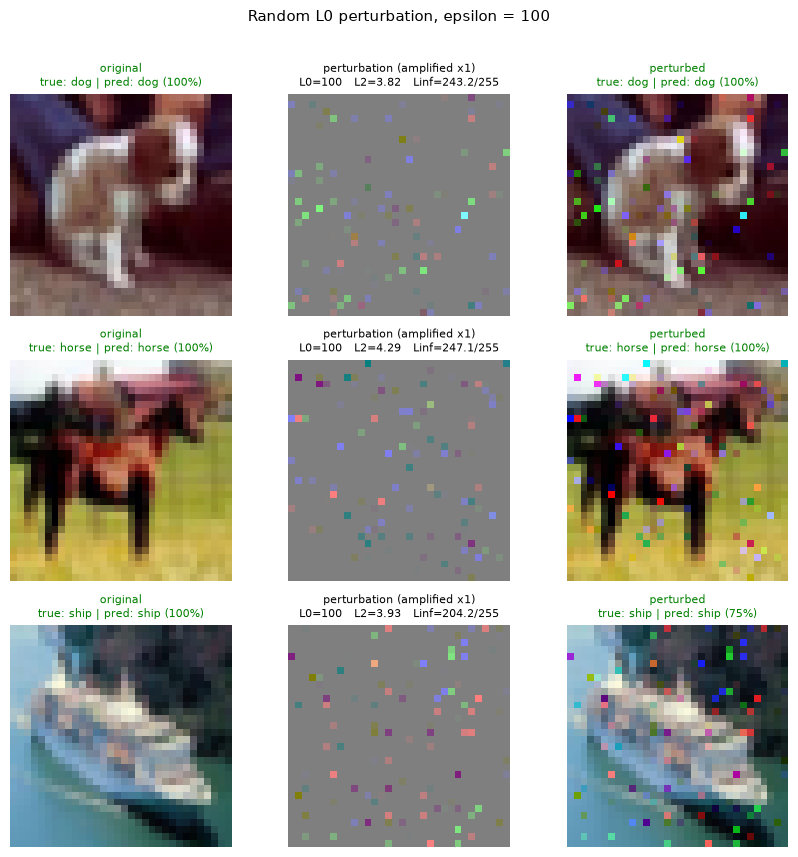

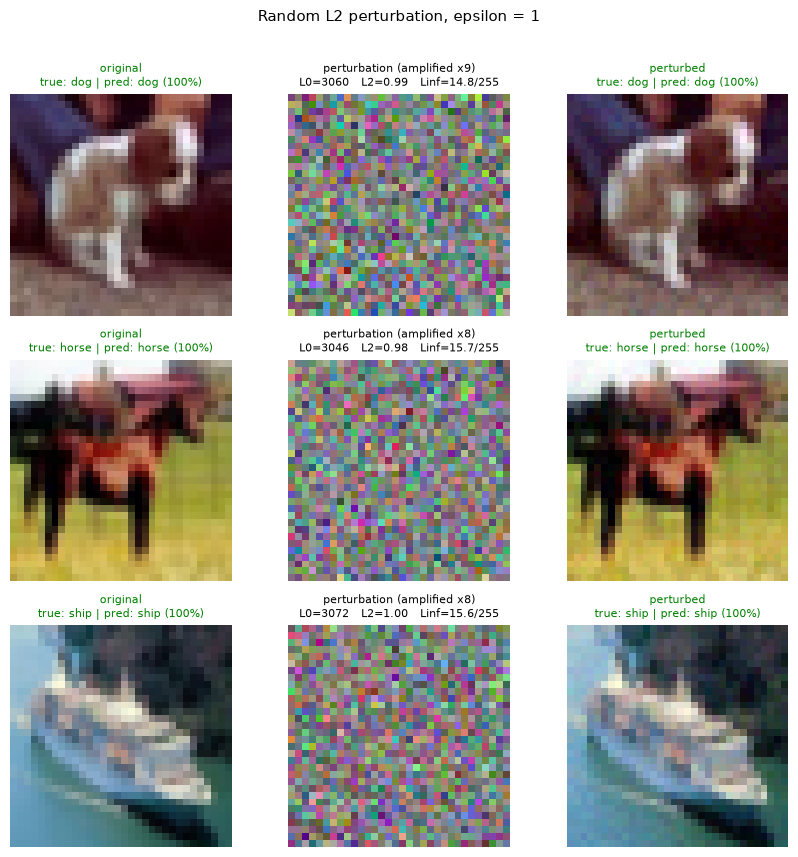

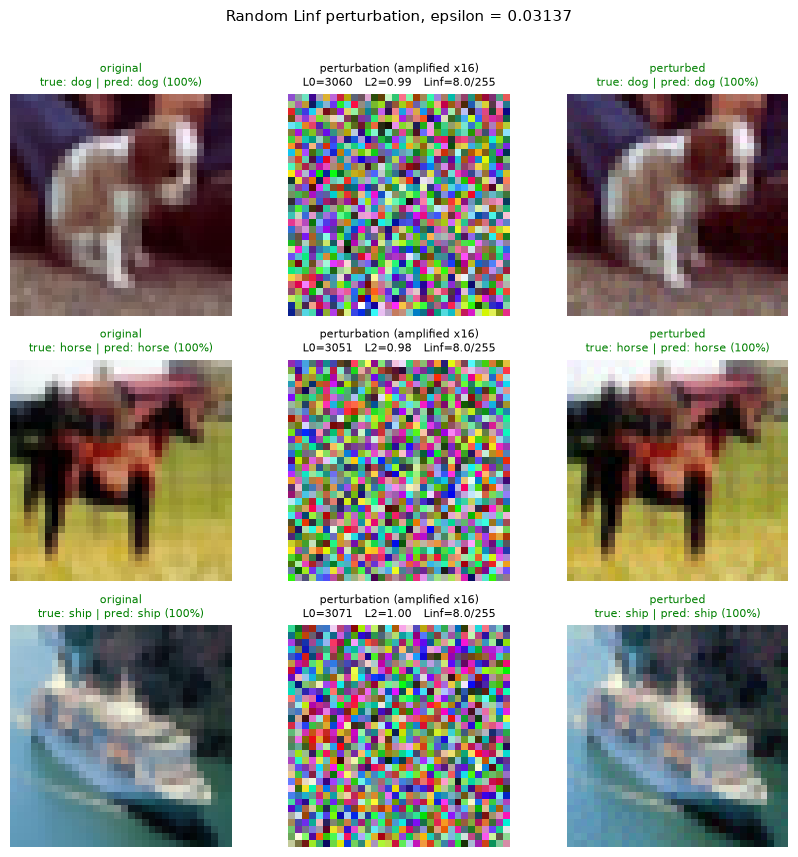

In [8]:
random_attacks = {
    'L0':   (perturb_image_L0,    [10, 50, 100, 300, 1000]),
    'L2':   (perturb_image_L2,    [0.25, 0.5, 1.0, 2.0, 4.0]),
    'Linf': (perturb_image_L_inf, [2/255, 4/255, 8/255, 16/255, 32/255]),
}


def measured_size(norm, delta):
    """The largest size of a perturbation in the batch, under the given norm, in pixel units."""
    flat = delta.flatten(1) / PIXEL_TO_NORM
    if norm == 'L0':
        return (flat != 0).sum(dim=1).max().item()
    if norm == 'L2':
        return flat.norm(dim=1).max().item()
    return flat.abs().max().item()


torch.manual_seed(0)
random_examples = {}
print(f'clean: accuracy={sample_acc:.4f}, micro F1={sample_micro_f1:.4f}, macro F1={sample_macro_f1:.4f}\n')
print(f'{"norm":<5} {"epsilon":>8} {"max size":>9} {"accuracy":>9} {"micro F1":>9} {"macro F1":>9}')
for norm, (perturb, epsilons) in random_attacks.items():
    for epsilon in epsilons:
        x_perturbed = torch.stack([perturb(image, epsilon) for image in x_sample])
        size = measured_size(norm, x_perturbed - x_sample)
        assert 0 < size <= epsilon + 1e-4, f'{norm} budget problem: size {size}, epsilon {epsilon}'
        assert x_perturbed.min() >= MIN_VALUE and x_perturbed.max() <= MAX_VALUE, 'not a valid image'
        acc, micro_f1, macro_f1 = evaluate(model, make_loader(x_perturbed))
        random_examples[norm, epsilon] = x_perturbed
        print(f'{norm:<5} {epsilon:>8.4g} {size:>9.4g} {acc:>9.4f} {micro_f1:>9.4f} {macro_f1:>9.4f}')

for key in [('L0', 100), ('L2', 1.0), ('Linf', 8/255)]:
    show_examples(model, x_sample, random_examples[key], y_sample, n=3, normalized=True,
                  title=f'Random {key[0]} perturbation, epsilon = {key[1]:.4g}')

**Choosing $\epsilon$.** We tested several budgets for each norm, because the meaning of $\epsilon$ is different in each one. Our main values are:

| norm | main $\epsilon$ | meaning | accuracy (clean: 81.3%) |
|---|---|---|---|
| $L_0$ | 100 | about 3% of the 3072 colour values may take any value | 59.4% |
| $L_2$ | 1.0 | the total length of the change in pixel units, spread over the whole image | 76.6% |
| $L_\infty$ | 8/255 | each colour value moves by at most about 3% of its range, a common budget for CIFAR-10 | 76.0% |

**Conclusions.**
* Random noise is a weak attack: at $L_\infty$ 8/255 the model loses only about 5 accuracy points. In high dimensions a random direction is rarely aligned with the directions that increase the loss, so large budgets are needed to do real damage (32/255 gives 25.8%).
* The $L_2$ and $L_\infty$ results agree with each other. A uniform perturbation in $[-\epsilon,\epsilon]$ has an expected squared length of $3072\,\epsilon^2/3$, so its $L_2$ size is about $32\epsilon$. This makes $L_\infty$ 8/255, 16/255 and 32/255 roughly equal to $L_2$ 1, 2 and 4, and the accuracies match: 76.0% vs 76.6%, 56.2% vs 55.6%, and 25.8% vs 27.3%.
* The $L_0$ budget is not directly comparable to the others, since each changed value can move by a large amount. Accuracy falls quickly as it grows, to 18.0% with 300 changed values.

These numbers are the baseline for Ex4: a gradient-based attack with the same budget should do far more damage than random noise.

#### $Ex4$. Below we added a pseudo-code algorithm for the Projected Gradient Descent (PGD) attack. Implement the attack in the cells below and run it on the same samples you tested in the previous part. Report accuracy, micro and macro f1.

 Note that:

* The attack is non-universal - you need to calulatea a unique perturbation for each image.
* Different combinations of hyper-parameters could different results. It is recommended to test multiple options and think of how they impact the attack's optimization process.

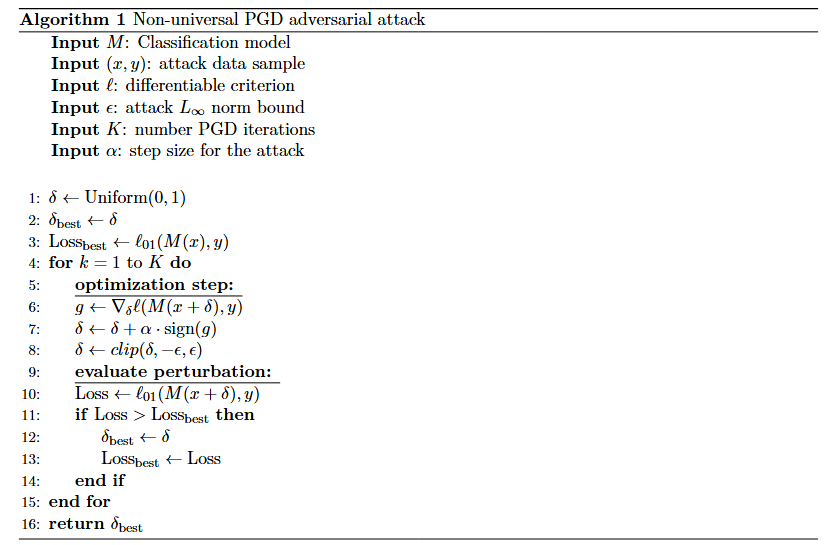

In [9]:
import torch.nn.functional as F


def zero_one_loss(model, x, y):
    """The 0-1 loss of every image in the batch: 1 if it is misclassified, otherwise 0."""
    with torch.no_grad():
        return (model(x).argmax(dim=1) != y).float()


def pgd_attack(model, x, y, epsilon, alpha, K, random_start=True, record_history=False):
    """Non-universal L_inf PGD (Algorithm 1) on a batch. Every image gets its own perturbation.
    epsilon and alpha are in pixel units. Returns the perturbed images x + delta_best
    (and the trajectory of the batch, if record_history is True)."""
    model.eval()
    x, y = x.to(device), y.to(device)
    eps, step = epsilon * PIXEL_TO_NORM, alpha * PIXEL_TO_NORM

    # Line 1, adapted: Uniform(0, 1) is far outside a small budget, so we sample inside [-eps, eps]
    delta = (2 * torch.rand_like(x) - 1) * eps if random_start else torch.zeros_like(x)
    delta = (x + delta).clamp(MIN_VALUE, MAX_VALUE) - x

    # Lines 2-3, adapted: we evaluate at x + delta, so that loss_best really is the loss of delta_best
    delta_best = delta.clone()
    loss_best = zero_one_loss(model, x + delta, y)
    history = [(x + delta).cpu()]

    for _ in range(K):
        # Optimization step (lines 6-8)
        delta.requires_grad_(True)
        # Summing keeps the images independent: the gradient for delta[i] depends only on image i
        loss = F.cross_entropy(model(x + delta), y, reduction='sum')
        g = torch.autograd.grad(loss, delta)[0]
        delta = delta.detach() + step * g.sign()  # a step UP the loss
        delta = delta.clamp(-eps, eps)
        delta = (x + delta).clamp(MIN_VALUE, MAX_VALUE) - x  # added to the algorithm: keep the image valid

        # Evaluate the perturbation (lines 10-14), separately for every image
        current_loss = zero_one_loss(model, x + delta, y)
        improved = current_loss > loss_best
        delta_best[improved] = delta[improved]
        loss_best[improved] = current_loss[improved]
        history.append((x + delta).cpu())

    x_adv = (x + delta_best).cpu()
    return (x_adv, torch.stack(history)) if record_history else x_adv


def run_pgd(epsilon, alpha, K, random_start=True):
    """Attacks the sample from Ex3, and returns the perturbed images and (accuracy, micro F1, macro F1)."""
    torch.manual_seed(0)
    x_adv = torch.cat([pgd_attack(model, x, y, epsilon, alpha, K, random_start)
                       for x, y in make_loader(x_sample)])
    assert measured_size('Linf', x_adv - x_sample) <= epsilon + 1e-4, 'L_inf budget exceeded'
    assert x_adv.min() >= MIN_VALUE and x_adv.max() <= MAX_VALUE, 'not a valid image'
    return x_adv, evaluate(model, make_loader(x_adv))

PGD, epsilon=8/255, alpha=2/255, K=20: accuracy=0.0000, micro F1=0.0000, macro F1=0.0000


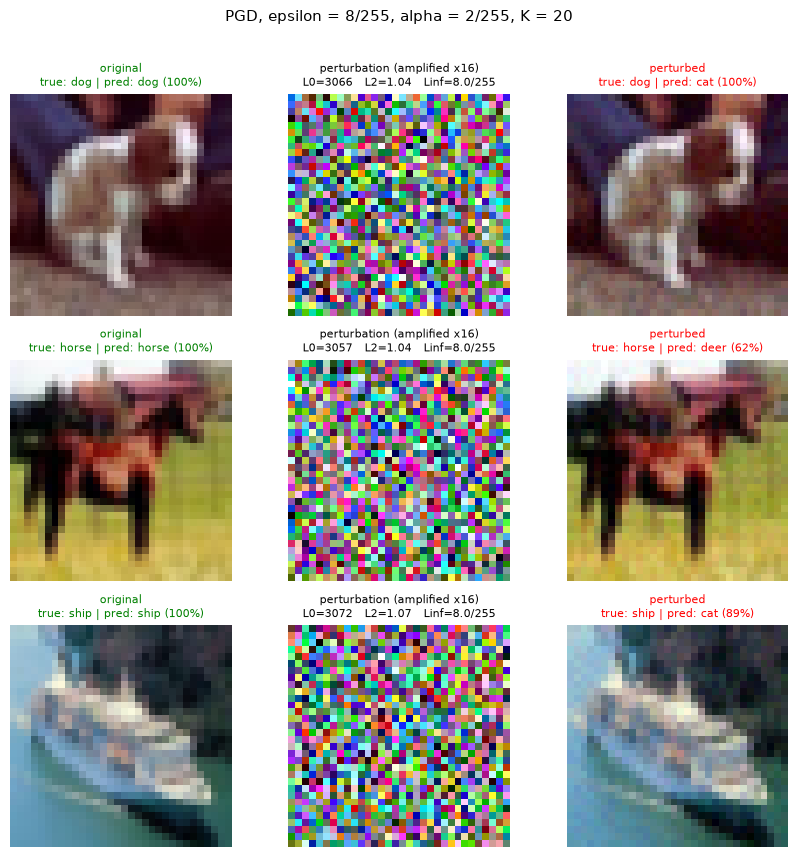

In [10]:
# Main result: the same L_inf budget as our main random perturbation in Ex3
x_pgd, (pgd_acc, pgd_micro_f1, pgd_macro_f1) = run_pgd(epsilon=8/255, alpha=2/255, K=20)
print(f'PGD, epsilon=8/255, alpha=2/255, K=20: accuracy={pgd_acc:.4f}, micro F1={pgd_micro_f1:.4f}, macro F1={pgd_macro_f1:.4f}')
show_examples(model, x_sample, x_pgd, y_sample, n=3, normalized=True, title='PGD, epsilon = 8/255, alpha = 2/255, K = 20')

In [11]:
def print_row(name, metrics):
    print(f'{name:<34} {metrics[0]:>9.4f} {metrics[1]:>9.4f} {metrics[2]:>9.4f}')

print(f'{"setting (pixel units)":<34} {"accuracy":>9} {"micro F1":>9} {"macro F1":>9}')
print_row('clean', (sample_acc, sample_micro_f1, sample_macro_f1))

print('\nEffect of epsilon (alpha = epsilon/4, K = 20)')
for n in [0.25, 0.5, 1, 2, 4]:
    print_row(f'epsilon = {n}/255', run_pgd(n/255, (n/255) / 4, 20)[1])

base_eps = 0.5/255   # a tight budget: with larger budgets nearly every setting reaches 0%, which hides the differences

print('\nEffect of alpha (epsilon = 0.5/255, K = 20)')
for ratio in [1/32, 1/16, 1/8, 1/4, 1/2, 1, 2]:
    print_row(f'alpha = {ratio:g} * epsilon', run_pgd(base_eps, base_eps * ratio, 20)[1])

print('\nEffect of K (epsilon = 0.5/255, alpha = epsilon/4)')
for K in [1, 2, 5, 10, 20, 40]:
    print_row(f'K = {K}', run_pgd(base_eps, base_eps / 4, K)[1])

print('\nEffect of the starting point (epsilon = 0.5/255, alpha = epsilon/4, K = 20)')
print_row('random start', run_pgd(base_eps, base_eps / 4, 20, random_start=True)[1])
print_row('delta = 0', run_pgd(base_eps, base_eps / 4, 20, random_start=False)[1])

setting (pixel units)               accuracy  micro F1  macro F1
clean                                 0.8130    0.8130    0.8201

Effect of epsilon (alpha = epsilon/4, K = 20)


epsilon = 0.25/255                    0.6520    0.6520    0.6691


epsilon = 0.5/255                     0.4340    0.4340    0.4625


epsilon = 1/255                       0.1400    0.1400    0.1685


epsilon = 2/255                       0.0030    0.0030    0.0039


epsilon = 4/255                       0.0000    0.0000    0.0000

Effect of alpha (epsilon = 0.5/255, K = 20)


... (11 outputs left out)

K = 20                                0.4340    0.4340    0.4625


K = 40                                0.4290    0.4290    0.4576

Effect of the starting point (epsilon = 0.5/255, alpha = epsilon/4, K = 20)


random start                          0.4340    0.4340    0.4625


delta = 0                             0.4320    0.4320    0.4604


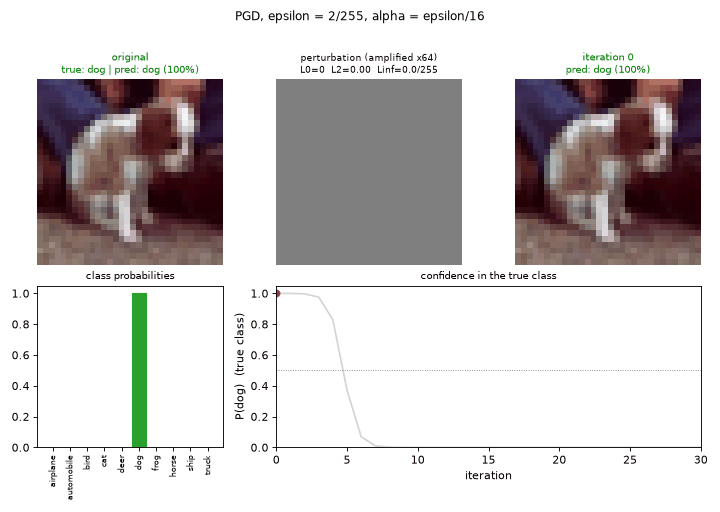

saved: attack_process.gif


In [12]:
# The attack process on one image: a correctly classified image that the attack manages to flip.
# Small budget and tiny steps from delta = 0, as suggested above, so the change is gradual.
gif_eps, gif_alpha, gif_K = 2/255, (2/255) / 16, 30

torch.manual_seed(0)
x_gif_candidates = torch.cat([pgd_attack(model, x, y, gif_eps, gif_alpha, gif_K, random_start=False)
                              for x, y in make_loader(x_sample[:128], y_sample[:128])])
with torch.no_grad():
    clean_preds = model(x_sample[:128].to(device)).argmax(dim=1).cpu()
    adv_preds = model(x_gif_candidates.to(device)).argmax(dim=1).cpu()
gif_idx = ((clean_preds == y_sample[:128]) & (adv_preds != y_sample[:128])).nonzero()[0].item()

x_one, y_one = x_sample[gif_idx], y_sample[gif_idx]
_, trajectory = pgd_attack(model, x_one.unsqueeze(0), y_one.unsqueeze(0), gif_eps, gif_alpha, gif_K,
                           random_start=False, record_history=True)
trajectory = trajectory.squeeze(1)  # [K+1, 1, 3, 32, 32] -> [K+1, 3, 32, 32]
animate_attack(model, x_one, trajectory, y_one.item(), normalized=True, title='PGD, epsilon = 2/255, alpha = epsilon/16')

**Results.** On the same 1000 images as Ex3, with $\epsilon = 8/255$, $\alpha = 2/255$ and $K = 20$:

| attack ($L_\infty$, $\epsilon = 8/255$) | accuracy | micro F1 | macro F1 |
|---|---|---|---|
| none (clean) | 81.3% | 0.813 | 0.820 |
| random noise (Ex3) | 76.0% | 0.760 | 0.768 |
| PGD | 0.0% | 0.000 | 0.000 |

Micro F1 equals accuracy in every experiment, because in a single-label task every wrong prediction counts as exactly one false positive and one false negative.

**Why it works.** With the same budget, random noise costs about 5 points and PGD costs all of them. The gradient shows which way to move each value to increase the loss, and for a small $L_\infty$ step the best direction under a first-order approximation is $\text{sign}(g)$. Repeating small steps and projecting back into the budget follows the loss as it changes. Since $\text{sign}(g)$ moves every value by the full step size, this makes full use of an $L_\infty$ budget.

**Effect of the hyper-parameters.**
* **$\epsilon$:** the larger the budget, the stronger the attack: 65.2% at 0.25/255, 14.0% at 1/255 and 0.3% at 2/255. Even 1/255 does far more damage than random noise at 32/255 (25.8%). Budgets below 1/255 are smaller than one 8-bit grey level, so they would not survive saving the image in a standard 8-bit format. We use them here only because they show the differences between settings, where larger budgets reach 0% for nearly every setting.
* **$\alpha$ (at $\epsilon = 0.5/255$, $K = 20$):** the best values are in the middle, with 43.4% at $\alpha = \epsilon/4$ and 43.5% at $\epsilon/2$. If $\alpha$ is too small the attack barely moves: at $\epsilon/32$, 20 steps cover at most $20/32$ of the budget, which gives 64.7%. If $\alpha$ is too large the steps overshoot and bounce between the edges of the budget, which gives 48.2% at $2\epsilon$.
* **$K$ (at $\epsilon = 0.5/255$, $\alpha = \epsilon/4$):** more iterations help, with diminishing returns: 74.7% at $K=1$, 52.0% at $K=5$, 43.4% at $K=20$ and 42.9% at $K=40$. With this $\alpha$, a value starting from $\delta = 0$ needs 4 steps just to reach the edge of the budget.
* **Starting point:** random start (43.4%) and $\delta = 0$ (43.2%) differ by only 2 images out of 1000, which is too small a difference to draw a conclusion from.

**Changes from Algorithm 1.**
1. We sample the starting point inside $[-\epsilon, \epsilon]$, because $\text{Uniform}(0,1)$ is far outside a small budget.
2. We compute the initial best loss at $x + \delta$ and not at $x$, so that it matches the $\delta_{best}$ stored next to it. Otherwise, an image that is misclassified when clean could keep a starting $\delta$ that the model classifies correctly.
3. We also clip to the valid range after every step, so that the result is a real image.

Because the selection uses the 0-1 loss, $\delta_{best}$ only changes the first time an image becomes misclassified. It is therefore the first successful perturbation, not the one with the highest cross-entropy loss. This does not affect accuracy or F1, which depend only on whether each image is misclassified.